# 02 – Data preparation & integration in SQLite
Goal: combine the three sources into **one analysis table** `analysis` and document every step (records lost/gained).

| Link | Key | Problem / solution |
|---|---|---|
| Actual data ↔ stations | `bpuic` (7-digit station number) | the actual data contains 7- and 9-digit numbers and SLOIDs → unified to 7 digits while loading |
| Actual data ↔ weather | `bpuic` + hour of the scheduled arrival | weather has an hourly resolution → arrival time rounded down to the full hour; daylight saving time change (duplicate hour) → first value |

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config
from src.db import get_connection

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config.OUTPUT_DIR.mkdir(exist_ok=True)
conn = get_connection()
print("Database:", config.DB_PATH.relative_to(ROOT))

Database: data/train_delays.sqlite


## 1. Data quality of the raw data (table `stops`)

In [2]:
quality = pd.read_sql("""
    SELECT arr_status,
           COUNT(*) AS n,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM stops WHERE arr_scheduled IS NOT NULL), 1) AS percent
    FROM stops
    WHERE arr_scheduled IS NOT NULL
    GROUP BY arr_status ORDER BY n DESC""", conn)
display(quality)

display(pd.read_sql("""
    SELECT COUNT(*) AS n_stops,
           SUM(cancelled) AS cancelled,
           SUM(CASE WHEN arr_delay_min < -10 OR arr_delay_min > 180 THEN 1 ELSE 0 END) AS implausible_delay,
           SUM(CASE WHEN arr_scheduled IS NULL THEN 1 ELSE 0 END) AS no_arrival_first_station
    FROM stops""", conn))

duplicates = pd.read_sql("""
    SELECT COUNT(*) AS groups_with_duplicates FROM (
        SELECT operating_day, trip_id, bpuic, COUNT(*) AS n FROM stops
        WHERE arr_scheduled IS NOT NULL
        GROUP BY 1, 2, 3 HAVING n > 1)""", conn)
display(duplicates)

,arr_status,n,percent
0,REAL,1768277,93.3
1,UNKNOWN,73927,3.9
2,FORECAST,53613,2.8


,n_stops,cancelled,implausible_delay,no_arrival_first_station
0,2078429,62995,491,182612


,groups_with_duplicates
0,763


## 2. Integration funnel: how many records remain after each step?

In [3]:
FILTER = "t.arr_scheduled IS NOT NULL AND t.cancelled = 0 AND t.arr_status = 'REAL' AND t.arr_delay_min BETWEEN -10 AND 180"
steps = {
    "1 All train stops (Switzerland)":            "SELECT COUNT(*) FROM stops t",
    "2 with scheduled arrival (no first station)": "SELECT COUNT(*) FROM stops t WHERE t.arr_scheduled IS NOT NULL",
    "3 not cancelled":                            "SELECT COUNT(*) FROM stops t WHERE t.arr_scheduled IS NOT NULL AND t.cancelled = 0",
    "4 measured actual time (status REAL)":       "SELECT COUNT(*) FROM stops t WHERE t.arr_scheduled IS NOT NULL AND t.cancelled = 0 AND t.arr_status = 'REAL'",
    "5 plausible delay (-10 to 180 min)":         f"SELECT COUNT(*) FROM stops t WHERE {FILTER}",
    "6 join with stations (coordinates/region)":  f"SELECT COUNT(*) FROM stops t JOIN stations s ON s.bpuic = t.bpuic WHERE {FILTER}",
    "7 join with weather (top stations)":         f"""SELECT COUNT(*) FROM stops t JOIN stations s ON s.bpuic = t.bpuic
                                                      JOIN weather w ON w.bpuic = t.bpuic AND w.time = strftime('%Y-%m-%d %H:00', t.arr_scheduled)
                                                      WHERE {FILTER}""",
}
funnel = pd.DataFrame({"step": list(steps),
                       "records": [conn.execute(q).fetchone()[0] for q in steps.values()]})
funnel["change_vs_previous"] = funnel["records"].diff().fillna(0).astype(int)
funnel["share_of_start_%"] = (100 * funnel["records"] / funnel["records"].iloc[0]).round(1)
display(funnel)

,step,records,change_vs_previous,share_of_start_%
0,1 All train stops (Switzerland),2078429,0,100.0
1,2 with scheduled arrival (no first station),1895817,-182612,91.2
2,3 not cancelled,1840569,-55248,88.6
3,4 measured actual time (status REAL),1768277,-72292,85.1
4,5 plausible delay (-10 to 180 min),1767800,-477,85.1
5,6 join with stations (coordinates/region),1767800,0,85.1
6,7 join with weather (top stations),400135,-1367665,19.3


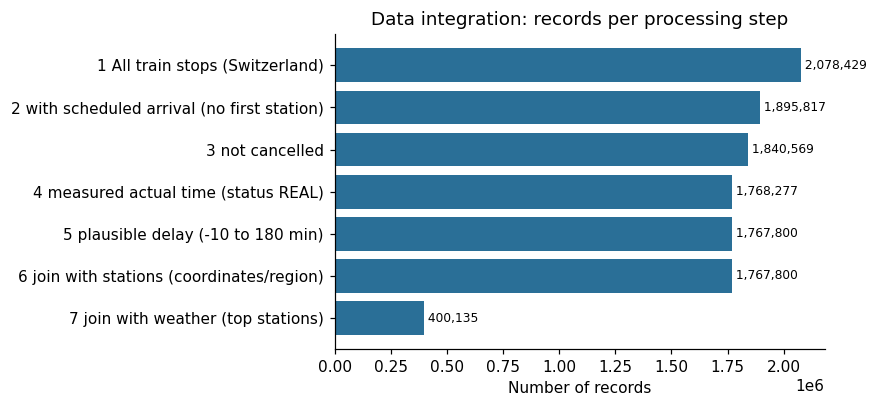

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(funnel["step"][::-1], funnel["records"][::-1], color="#2a6f97")
for y, v in enumerate(funnel["records"][::-1]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8)
ax.set_xlabel("Number of records")
ax.set_title("Data integration: records per processing step")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "02_integration_funnel.png", dpi=200); plt.show()

Which stations in the actual data found **no match** in the station master data?

In [5]:
display(pd.read_sql("""
    SELECT t.bpuic, t.stop_name, COUNT(*) AS n_stops
    FROM stops t LEFT JOIN stations s ON s.bpuic = t.bpuic
    WHERE s.bpuic IS NULL
    GROUP BY t.bpuic, t.stop_name ORDER BY n_stops DESC LIMIT 10""", conn))

,bpuic,stop_name,n_stops


## 3. Create the analysis table
Duplicates (same trip, same day, same station) are removed with `ROW_NUMBER()`.

In [6]:
conn.executescript("""
DROP TABLE IF EXISTS analysis;
CREATE TABLE analysis AS
SELECT operating_day, trip_id, operator, train_type, line, bpuic, station, canton, region, lat, lon,
       arr_scheduled, arr_delay_min, temperature, precipitation, snowfall, wind
FROM (
    SELECT t.operating_day, t.trip_id, t.operator, t.train_type, t.line, t.bpuic,
           s.name AS station, s.canton, s.region, s.lat, s.lon,
           t.arr_scheduled, t.arr_delay_min,
           w.temperature, w.precipitation, w.snowfall, w.wind,
           ROW_NUMBER() OVER (PARTITION BY t.operating_day, t.trip_id, t.bpuic ORDER BY t.arr_scheduled) AS rn
    FROM stops t
    JOIN stations s ON s.bpuic = t.bpuic
    JOIN weather  w ON w.bpuic = t.bpuic AND w.time = strftime('%Y-%m-%d %H:00', t.arr_scheduled)
    WHERE t.arr_scheduled IS NOT NULL AND t.cancelled = 0 AND t.arr_status = 'REAL'
      AND t.arr_delay_min BETWEEN -10 AND 180
)
WHERE rn = 1;
CREATE INDEX IF NOT EXISTS idx_analysis_bpuic ON analysis(bpuic);
""")
n_analysis = conn.execute("SELECT COUNT(*) FROM analysis").fetchone()[0]
print(f"Analysis table: {n_analysis:,} rows  (duplicates removed: {funnel['records'].iloc[-1] - n_analysis:,})")
display(pd.read_sql("SELECT * FROM analysis LIMIT 5", conn))

Analysis table: 400,135 rows  (duplicates removed: 0)


,operating_day,trip_id,operator,train_type,line,bpuic,station,canton,region,lat,lon,arr_scheduled,arr_delay_min,temperature,precipitation,snowfall,wind
0,2026-10-14,80:800693:3040:000,DB Regio,RE,RE3,8503424,Schaffhausen,SH,German-speaking,47.698282,8.632756,2026-10-14 05:54:00,1.28,10.8,0.0,0.0,4.0
1,2026-10-14,80:800693:3041:000,DB Regio,RE,RE3,8503424,Schaffhausen,SH,German-speaking,47.698282,8.632756,2026-10-14 06:14:00,0.28,10.2,0.0,0.0,3.6
2,2026-10-14,80:800693:3042:000,DB Regio,RE,RE3,8503424,Schaffhausen,SH,German-speaking,47.698282,8.632756,2026-10-14 06:58:00,0.60,10.2,0.0,0.0,3.6
3,2026-10-14,80:800693:3043:000,DB Regio,RE,RE3,8503424,Schaffhausen,SH,German-speaking,47.698282,8.632756,2026-10-14 06:58:00,2.00,10.2,0.0,0.0,3.6
4,2026-10-14,80:800693:3044:000,DB Regio,RE,RE3,8503424,Schaffhausen,SH,German-speaking,47.698282,8.632756,2026-10-14 07:58:00,1.95,10.3,0.0,0.0,2.7


In [7]:
display(pd.read_sql("""
    SELECT region, COUNT(DISTINCT bpuic) AS stations, COUNT(*) AS arrivals,
           ROUND(AVG(arr_delay_min), 2) AS mean_delay_min,
           ROUND(100.0 * AVG(arr_delay_min >= 3), 1) AS share_late_percent
    FROM analysis GROUP BY region ORDER BY arrivals DESC""", conn))

,region,stations,arrivals,mean_delay_min,share_late_percent
0,German-speaking,78,321461,0.75,5.8
1,Romandy,17,63536,0.77,8.8
2,Ticino,5,15138,0.89,7.1
